# PAMR-GA — Example

A runnable tour of PAMR-GA: inspect the pocket map and curated BACE-1 dataset,
run one crossover, then run an actual (small, fast) live slice of the
pipeline — training a demo-scale GPR surrogate and a few real genetic-algorithm
generations using the same `pamr_ga.py` code the full pipeline uses. Expected
runtime for the whole notebook: a few minutes.

This does **not** reproduce the paper's reported results — the live-training
sections here use a deliberately small molecule subset for speed. See the main
[README](../README.md) for the full, scientifically meaningful run.

Run from the `notebooks/` directory with the `pamr_ga` conda environment
(`conda env create --file ../env.yml && conda activate pamr_ga`).

In [1]:
import os
import random
import pickle
import pandas as pd
import sys

sys.path.append('..')  # so `import crossover`, `import pamr_ga` resolve to the repo root

from rdkit import Chem
from rdkit.Chem import Draw
import crossover as co

## 1. Inspect the SAR-derived pocket map

`data/pocket_map.pkl` is inverse-engineered from BACE-1 activity cliffs (see `scripts/pocket_map.py`) and constrains the genetic algorithm's fitness function.

In [2]:
with open('../data/pocket_map.pkl', 'rb') as f:
    pocket = pickle.load(f)

print(f"Pocket volume ceiling (v_max): {pocket['v_max']:.1f} Å³")
print(f"Hydrogen-bond hotspots: {len(pocket['hotspots'])}")
for h in pocket['hotspot_details']:
    print(f"  - {h['family']:<10} consensus={h['consensus']:.2f}  (seen in {h['n_mols']} actives)")
print(f"Exclusion spheres: {len(pocket['exclusion_spheres'])} (radius {pocket['exclusion_spheres'][0][1]} Å each)")
print(f"Inferred from {pocket['n_actives_used']} active molecules (pIC50 >= {pocket['active_threshold']})")

Pocket volume ceiling (v_max): 482.1 A^3
Hydrogen-bond hotspots: 4
  - Acceptor   consensus=0.70  (seen in 328 actives)
  - Acceptor   consensus=0.53  (seen in 245 actives)
  - Donor      consensus=0.45  (seen in 211 actives)
  - Acceptor   consensus=0.41  (seen in 189 actives)
Exclusion spheres: 5 (radius 1.5 A each)
Inferred from 466 active molecules (pIC50 >= 8.0)


## 2. Curated BACE-1 dataset

`data/bace1_dataset.csv` holds the ChEMBL-derived bioactivity data (target CHEMBL4822) used to train the GPR surrogate.

In [3]:
df = pd.read_csv('../data/bace1_dataset.csv')
print(f"{len(df)} molecules, pIC50 range {df.pIC50.min():.2f}-{df.pIC50.max():.2f}, mean {df.pIC50.mean():.2f}")
df.head()

8044 molecules, pIC50 range 4.00-12.00, mean 6.79


chembl_id,canonical_smiles,pIC50
CHEMBL406146,CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O)O)C(C)C)C(=O)N[C@@H](Cc1ccccc1)[C@@H](O)C(=O)N[C@@H](CC(=O)O)C(=O)N[C@@H](C)C(=O)N[C@@H](CCC(=O)O)C(=O)N[C@@H](Cc1ccccc1)C(=O)O,6.384050
CHEMBL78946,CC(C)C[C@H](NC(=O)[C@H](CC(N)=O)NC(=O)[C@@H](NC(=O)[C@@H](N)CCC(=O)O)C(C)C)[C@@H](O)C[C@@H](C)C(=O)N[C@@H](C)C(=O)N[C@@H](CCC(=O)O)C(=O)N[C@@H](Cc1ccccc1)C(=O)O,8.698970
CHEMBL324109,CCC(C)C[C@H](NC(=O)[C@H](CC(C)C)NC(C)=O)[C@@H](O)CC(=O)NC(CCSC)[C@@H](O)CC(=O)N[C@H](C(=O)NCc1ccc(C(=O)O)cc1)C(C)C,6.337242
CHEMBL114147,CC(=O)NCC(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)N[C@@H](CC1CCCCC1)[C@@H](O)CC(=O)N[C@H](C(=O)NCc1ccc(C(=O)O)cc1)C(C)C,5.045757
CHEMBL419949,CC(=O)N[C@@H](Cc1ccccc1)C(=O)N[C@@H](Cc1ccccc1)[C@@H](O)CC(=O)N[C@@H](CC1CCCCC1)[C@@H](O)CC(=O)N[C@H](C(=O)NCc1ccc(C(=O)O)cc1)C(C)C,5.251812


## 3. Visualize a few high-potency actives

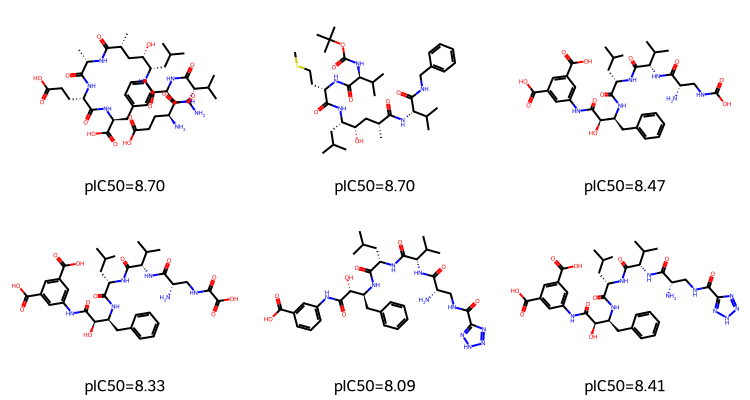

In [4]:
actives = df[df.pIC50 >= 8.0].head(6)
mols = [Chem.MolFromSmiles(s) for s in actives.canonical_smiles]
Draw.MolsToGridImage(mols, molsPerRow=3, subImgSize=(250, 200),
                      legends=[f"pIC50={v:.2f}" for v in actives.pIC50])

## 4. One crossover operation

`crossover.crossover()` expects `co.average_size` / `co.size_stdev` to be
set first — `pamr_ga.py` does this from its own `CO_AVERAGE_SIZE` /
`CO_SIZE_STDEV` constants before calling it. We mirror that here; without it,
`crossover()` silently returns `None` every time.

child SMILES: CC(C)C[C@H](NC(=O)[C@@H](NC(=O)[C@@H](NC(=O)OC(C)(C)C)C(C)C)N[C@@H](Cc1ccccc1)C(=O)O)[C@@H](O)C[C@@H](C)C(=O)N[C@H](C(=O)NCc1ccccc1)C(C)C


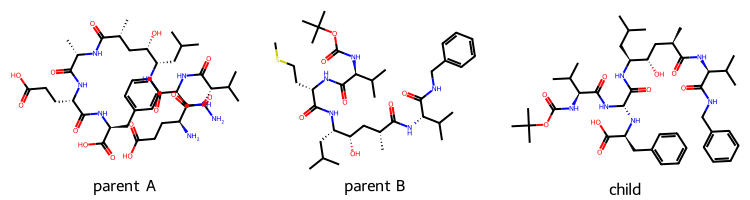

In [5]:
co.average_size = 30   # matches CO_AVERAGE_SIZE in pamr_ga.py
co.size_stdev = 40      # matches CO_SIZE_STDEV in pamr_ga.py

random.seed(7)
parent_a, parent_b = mols[0], mols[1]
child = None
for attempt in range(20):
    child = co.crossover(parent_a, parent_b)
    if child is not None:
        break

print("child SMILES:", Chem.MolToSmiles(child))
Draw.MolsToGridImage([parent_a, parent_b, child], molsPerRow=3, subImgSize=(250, 200),
                      legends=['parent A', 'parent B', 'child'])

## 5. Train a demo-scale GPR surrogate

The real surrogate (`scripts/train_gpr_peoe.py`) computes a 5-conformer
SASA×PEOE descriptor for all ~8,000 curated molecules and trains on ~6,400 of
them — each descriptor takes a few seconds, so a full run takes hours. For
this notebook we call the exact same `get_sasa_peoe_descriptor()` /
`TanimotoKernel` code on a 100-molecule random subset instead, purely so the
demo finishes in a couple of minutes. The resulting model is **not**
scientifically meaningful (test R² is expected to be poor, even negative) —
it exists only to feed real scores into the GA step below.

In [6]:
import importlib
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.gaussian_process import GaussianProcessRegressor
from sklearn.metrics import r2_score

sys.path.append('../scripts')
train_mod = importlib.import_module('train_gpr_peoe')

TRAIN_SUBSET_N = 100
subset = df.sample(n=TRAIN_SUBSET_N, random_state=0)

X_list, y_list = [], []
for row in subset.itertuples():
    vec = train_mod.get_sasa_peoe_descriptor(row.canonical_smiles)
    if vec is not None:
        X_list.append(vec)
        y_list.append(row.pIC50)
X = np.array(X_list, dtype=np.float32)
y = np.array(y_list)
print(f"{len(X)}/{len(subset)} molecules succeeded")

100/100 molecules succeeded


In [7]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

y_scaler = StandardScaler()
y_train_scaled = y_scaler.fit_transform(y_train.reshape(-1, 1)).ravel()
X_scaler = StandardScaler()
X_train_scaled = X_scaler.fit_transform(X_train)
X_test_scaled = X_scaler.transform(X_test)

gpr = GaussianProcessRegressor(kernel=train_mod.TanimotoKernel(), alpha=0.1, n_restarts_optimizer=5)
gpr.fit(X_train_scaled, y_train_scaled)

y_pred = y_scaler.inverse_transform(gpr.predict(X_test_scaled).reshape(-1, 1)).ravel()
r2 = r2_score(y_test, y_pred)
print(f"Demo-scale test R²: {r2:.3f} (n_train={len(X_train)}, n_test={len(X_test)})")
print("(The paper's real model trains on ~6400 molecules and reports R² ≈ 0.66)")

scaler = {'mean': float(y_scaler.mean_[0]), 'std': float(y_scaler.scale_[0]), 'X_scaler': X_scaler}

Demo-scale test R²: -0.266 (n_train=80, n_test=20)
(The paper's real model trains on ~6400 molecules and reports R² ≈ 0.66)


## 6. Run a few real GA generations

`pamr_ga.GB_GA()` is the exact generation-step function the full pipeline
calls 50 times in a row. Here we call it directly, 3 times, on a small
10-molecule starting pool, after pointing its module-level `TARGET_POOL` at
20 instead of 1000 (a runtime override on the imported module — `pamr_ga.py`
itself is untouched) so each generation only needs to produce a handful of
offspring. `co.average_size` / `co.size_stdev` are set the same way
`pamr_ga.main()` sets them before calling the GA.

In [8]:
import pamr_ga

with open('../data/bace1_initpool.dat') as f:
    pool_lines = [l.strip() for l in f if l.strip() and l.strip() != 'SMILES']
with open('../mutate_reaction.dat') as f:
    rxn_list = [line.rstrip() for line in f if line.strip()]

random.seed(2026)
np.random.seed(2026)

GenPool = pool_lines[:10]
pamr_ga.TARGET_POOL = 20                       # was 1000 — small pool for a fast demo
pamr_ga.co.average_size = pamr_ga.CO_AVERAGE_SIZE
pamr_ga.co.size_stdev   = pamr_ga.CO_SIZE_STDEV

results_dir = 'results'                        # notebooks/results/ — gitignored, separate from the repo's own results/
os.makedirs(os.path.join(results_dir, 'steps'), exist_ok=True)

desc_cache = {}
for istep in range(3):
    GenPool = pamr_ga.GB_GA(gpr, scaler, GenPool, istep, pocket, rxn_list, results_dir, desc_cache)

     1     2.81841 /  7.05215 /  0.59238      20 (    10 +     10)      10       5
     2     2.81937 /  7.75643 /  0.48082      19 (     8 +     12)      12       5
     3     2.51493 /  8.11317 /  0.30736      19 (     5 +     15)      15       5


## 7. Inspect and visualize the result

In [9]:
pamr_ga.collect_top_molecules(results_dir, top_n=20)
top = pd.read_csv(os.path.join(results_dir, 'all_top_molecules.csv'))
top.head(10)


  Top molecules saved: results/all_top_molecules.csv
  Unique candidates:   35
  Best S_final:        15.486
  Mean S_final:        10.081



SMILES,S_final,S_GPR,step
CC#CCOc1cnc(C(=O)NC=CBr)cn1,15.485802,7.485802,1
CC=C(F)[C@@]12CN(c3ncc(F)cn3)C[C@@H]1CS(=O)(=O)C(N)=N2,14.453329,7.453329,3
CC#CCOc1cnc(C(=O)NC)cn1,13.717899,6.717899,2
CC#CCOc1cnc(C(=O)O)cn1,13.243211,7.243211,3
C#Cc1ccc(F)c([C@@]23CN(c4ncc(F)cn4)C[C@@H]2CS(=O)C(C#CN)=N3)c1,11.800681,6.800681,3
C[C@]1(F)COC(N)=N[C@]1(C)c1cc(NC(=O)c2ccc(C#N)cn2)ccc1F,11.240129,7.240129,1
CC#CCOc1cnc(C(=O)NF)cn1,11.024088,7.024088,1
CC#CCOc1ncc(F)cn1,10.711283,6.711283,3
N#Cc1ccc(-c2cc(NC(=O)c3ncc(C#N)cc3Br)ccc2F)nc1,10.132697,7.132697,1
O=C=NC=CF,9.900217,6.900217,1


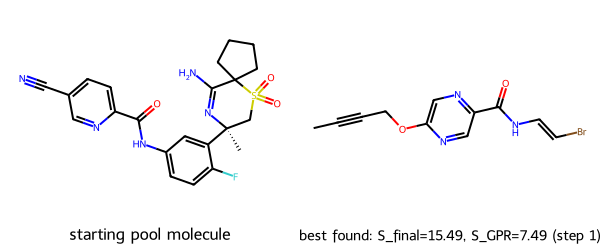

In [10]:
best = top.iloc[0]
start_mol = Chem.MolFromSmiles(pool_lines[0])
best_mol = Chem.MolFromSmiles(best.SMILES)
Draw.MolsToGridImage(
    [start_mol, best_mol], molsPerRow=2, subImgSize=(300, 250),
    legends=['starting pool molecule',
             f"best found: S_final={best.S_final:.2f}, S_GPR={best.S_GPR:.2f} (step {int(best.step)})"]
)

With only 100 training molecules, the demo surrogate doesn't correlate with
real binding affinity (test R² above is negative) — the "best" molecule
found here is not a real BACE-1 inhibitor candidate. This section
demonstrates that selection, crossover, reaction-rule mutation, GPR scoring,
and pocket-constraint filtering all run correctly end-to-end against the
actual code, not a reproduction of the paper's results. For real candidates,
follow the main [README](../README.md) with the full dataset.

## Your experiments

Add your own cells below — e.g. load a fully-trained
`models/gpr_peoe_bace1.pkl` (after running `scripts/train_gpr_peoe.py` for
real) in place of the demo `gpr`/`scaler` above, score custom SMILES, or
chain more generations together.